# Titanic EDA: Session 3, Exercise #2
**Data Science & Generative AI**: exploratory data analysis following the five-step process from the seminar (slide 15):
univariate analysis, bivariate analysis, outliers, missing values, feature engineering.

**Run it:** upload `titanic.csv` to Colab (or keep it next to this notebook) and run all cells. Each code block is short and does one job, as the seminar's AI best practices recommend.

**One thing to know before reading any result.** This file has 891 passengers. Britannica puts the total on board at about 2,200 with about 705 survivors, roughly 32% ([Britannica](https://www.britannica.com/question/How-many-people-survived-the-sinking-of-the-Titanic)). Our file shows 38.4% survived, so it is a partial sample, apparently without most of the crew. Everything below describes this sample, not the whole ship.

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold", "axes.spines.top": False, "axes.spines.right": False})
PAL = {"died": "#c8553d", "lived": "#2a6f97", "grey": "#8d99ae"}

df = pd.read_csv("titanic.csv")
print(df.shape)
df.head()

(891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


## 0. First look: what are we dealing with?

In [2]:
print(df.dtypes.to_string())
print()
print("Duplicate rows:", df.duplicated().sum(), "| PassengerId unique:", df.PassengerId.is_unique)
miss = df.isna().sum()
miss[miss > 0].to_frame("missing").assign(pct=lambda d: (d.missing / len(df) * 100).round(1))

PassengerId      int64
Survived         int64
Pclass           int64
Name               str
Sex                str
Age            float64
SibSp            int64
Parch            int64
Ticket             str
Fare           float64
Cabin              str
Embarked           str

Duplicate rows: 0 | PassengerId unique: True


,missing,pct
Age,177,19.9
Cabin,687,77.1
Embarked,2,0.2


The structure is clean: no duplicate rows, every `PassengerId` unique. The mess is in three columns: **Cabin** (77% missing), **Age** (20%) and **Embarked** (2 rows). Step 4 deals with these. Note that `Survived`, `Pclass` and `Embarked` are categories stored as numbers or text, so means of `Survived` are survival *rates*, but the mean of `Pclass` is meaningless.

## 1. Univariate analysis: each variable on its own

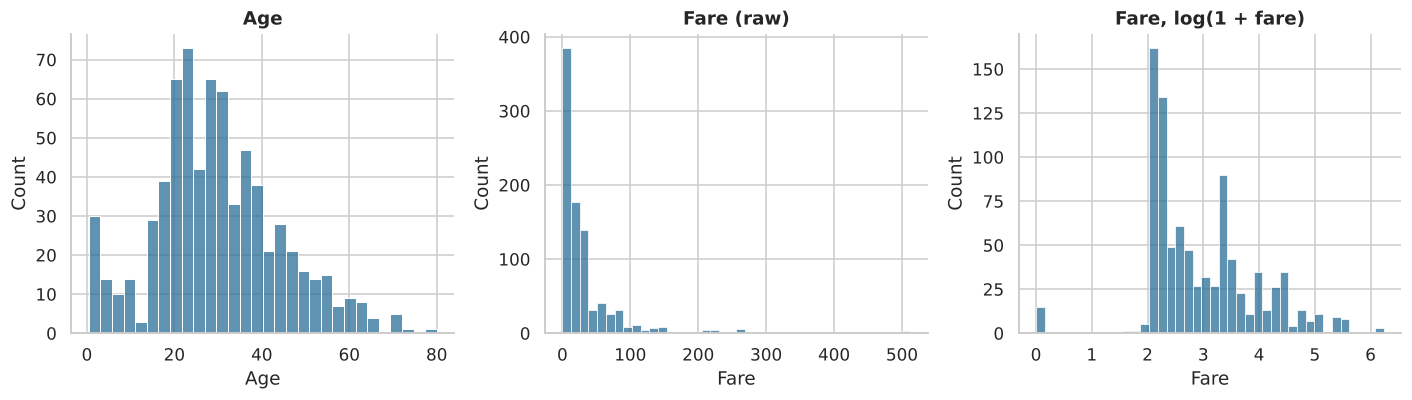

Skew: Age = 0.39 | Fare = 4.79 | log Fare = 0.39


In [3]:
fig, ax = plt.subplots(1, 3, figsize=(13, 3.8))
sns.histplot(df.Age.dropna(), bins=30, color=PAL["lived"], ax=ax[0]); ax[0].set_title("Age")
sns.histplot(df.Fare, bins=40, color=PAL["lived"], ax=ax[1]); ax[1].set_title("Fare (raw)")
sns.histplot(np.log1p(df.Fare), bins=40, color=PAL["lived"], ax=ax[2]); ax[2].set_title("Fare, log(1 + fare)")
plt.tight_layout(); plt.show()
print("Skew: Age =", round(df.Age.skew(), 2), "| Fare =", round(df.Fare.skew(), 2), "| log Fare =", round(np.log1p(df.Fare).skew(), 2))

- **Age** is roughly bell-shaped (skew 0.39) with a bump of infants and young children at the left. The median is 28.
- **Fare** is extremely right-skewed (skew 4.79). Most people paid under £31, a handful paid over £500. A log transform pulls the skew down to a manageable level, which is why we will use it for plots and any model later.

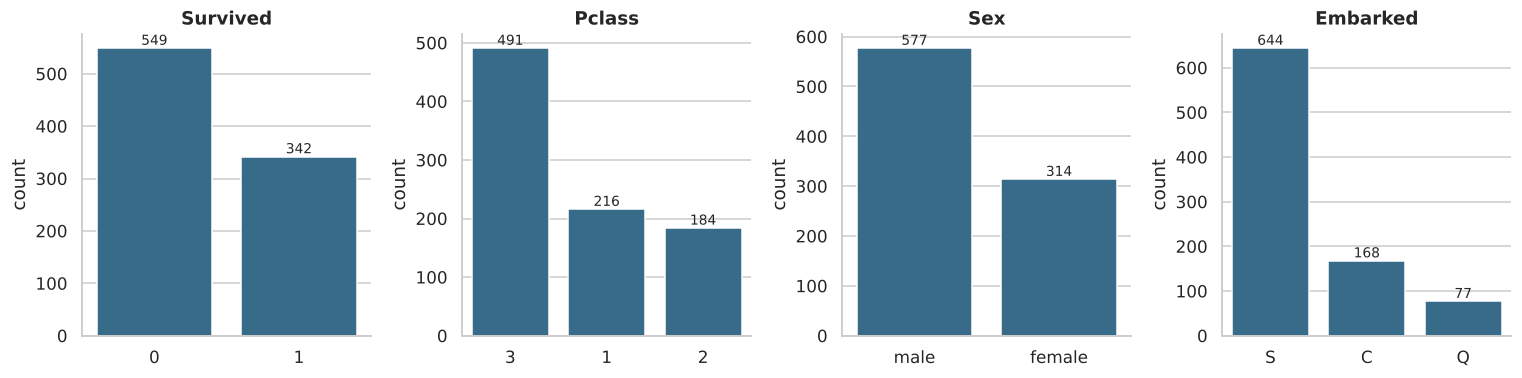

In [4]:
fig, ax = plt.subplots(1, 4, figsize=(14, 3.6))
for a, col in zip(ax, ["Survived", "Pclass", "Sex", "Embarked"]):
    order = df[col].value_counts().index
    sns.countplot(data=df, x=col, order=order, color=PAL["lived"], ax=a)
    a.set_title(col); a.set_xlabel("")
    for p in a.patches:
        a.annotate(int(p.get_height()), (p.get_x() + p.get_width() / 2, p.get_height()), ha="center", va="bottom", fontsize=9)
plt.tight_layout(); plt.show()

Class balance matters for everything that follows: 549 died and 342 lived (38%). Third class is the majority (491 of 891), men outnumber women almost 2 to 1 (577 vs 314), and 72% boarded at Southampton. Any "average" we compute is dominated by third-class men, so we should always look at subgroups.

## 2. Bivariate analysis: what goes with survival?

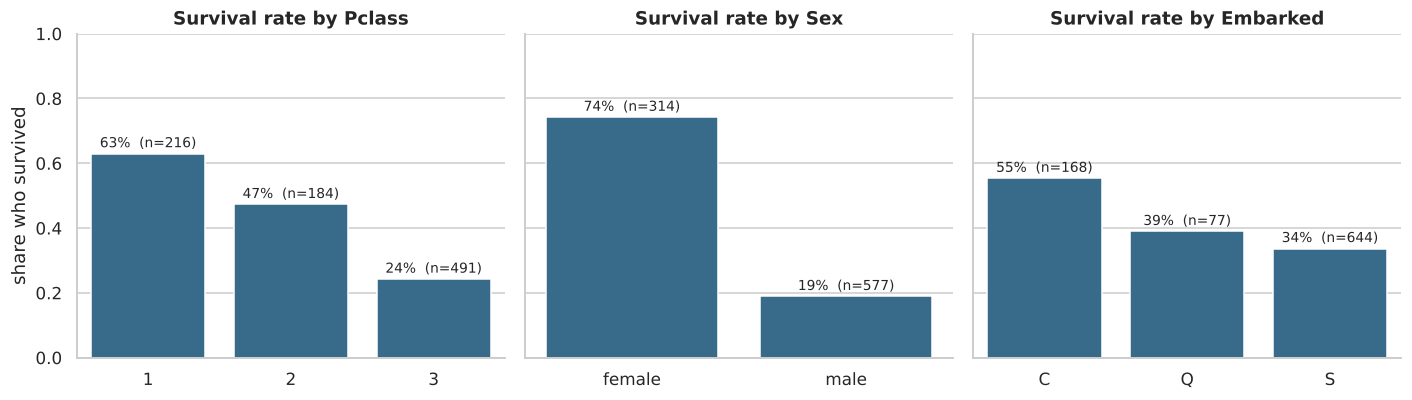

In [5]:
fig, ax = plt.subplots(1, 3, figsize=(13, 3.8), sharey=True)
for a, col in zip(ax, ["Pclass", "Sex", "Embarked"]):
    rate = df.groupby(col).Survived.mean()
    sns.barplot(x=rate.index, y=rate.values, color=PAL["lived"], ax=a)
    a.set_title(f"Survival rate by {col}"); a.set_xlabel(""); a.set_ylim(0, 1)
    for i, (k, v) in enumerate(rate.items()):
        a.text(i, v + 0.02, f"{v:.0%}  (n={int((df[col] == k).sum())})", ha="center", fontsize=9)
ax[0].set_ylabel("share who survived")
plt.tight_layout(); plt.show()

Two huge effects: **sex** (74% of women survived vs 19% of men) and **class** (63% first, 47% second, 24% third). Embarkation port also differs (Cherbourg 55%, Queenstown 39%, Southampton 34%), but be suspicious of it. Before reading it as a "port effect", check whether it is just class in disguise.

In [6]:
print("Class mix by port (row %):")
print((pd.crosstab(df.Embarked, df.Pclass, normalize="index") * 100).round(0).astype(int).to_string())

Class mix by port (row %):
Pclass     1   2   3
Embarked            
C         51  10  39
Q          3   4  94
S         20  25  55


Cherbourg is 51% first class, Queenstown is 94% third class. The port effect is largely a class effect. This is a textbook confounder: the bivariate chart is true, but the story "boarding at Cherbourg saved you" is not supported by it.

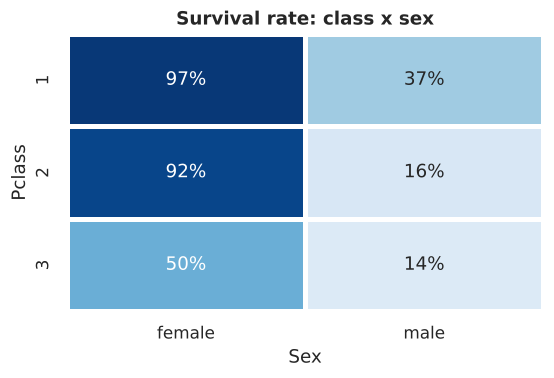

Sex,female,male
Pclass,,
1,94,122
2,76,108
3,144,347


In [7]:
tab = df.pivot_table(index="Pclass", columns="Sex", values="Survived", aggfunc="mean")
cnt = df.pivot_table(index="Pclass", columns="Sex", values="Survived", aggfunc="count")
fig, ax = plt.subplots(figsize=(5.2, 3.6))
sns.heatmap(tab, annot=True, fmt=".0%", cmap="Blues", vmin=0, vmax=1, cbar=False, ax=ax, linewidths=2, linecolor="white")
ax.set_title("Survival rate: class x sex"); plt.tight_layout(); plt.show()
cnt

Sex and class combine rather than just add up. Almost every first- and second-class woman survived (97% and 92%), but only **half** of third-class women did (50%). Third-class men were the worst off at 14%. First-class men (37%) did better than men in the other classes, but still far worse than women in any class.

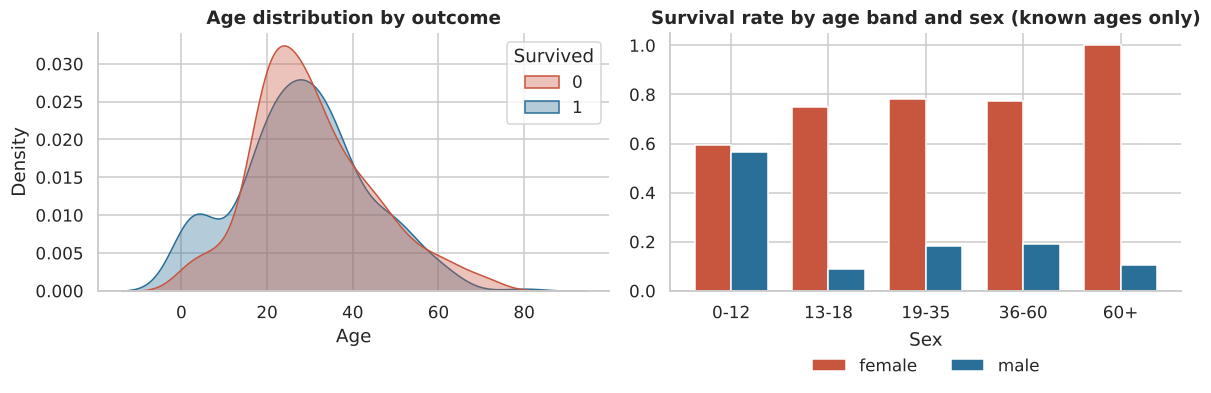

mean        count     
Sex     female  male female male
AgeBand                         
0-12      0.59  0.57     32   37
13-18     0.75  0.09     36   34
19-35     0.78  0.18    120  238
36-60     0.77  0.19     70  125
60+       1.00  0.11      3   19

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
sns.kdeplot(data=df, x="Age", hue="Survived", common_norm=False, fill=True, alpha=.35,
            palette={0: PAL["died"], 1: PAL["lived"]}, ax=ax[0]); ax[0].set_title("Age distribution by outcome")
d = df.dropna(subset=["Age"]).copy()
d["AgeBand"] = pd.cut(d.Age, [0, 12, 18, 35, 60, 100], labels=["0-12", "13-18", "19-35", "36-60", "60+"])
r = d.groupby(["AgeBand", "Sex"], observed=True).Survived.mean().unstack()
r.plot(kind="bar", ax=ax[1], color=[PAL["died"], PAL["lived"]], width=.75, rot=0)
ax[1].set_title("Survival rate by age band and sex (known ages only)"); ax[1].set_xlabel(""); ax[1].set_ylim(0, 1.05)
ax[1].legend(title="Sex", loc="upper center", bbox_to_anchor=(.5, -.1), ncol=2, frameon=False)
plt.tight_layout(); plt.show()
d.groupby(["AgeBand", "Sex"], observed=True).Survived.agg(["mean", "count"]).round(2).unstack()

Age alone looks weak (correlation with survival of only -0.08) because the effect is not a straight line. The right-hand chart shows why: **boys aged 0-12 survived at about the same rate as girls (57% vs 59%)**, but from the teens on males survive at only 9-19% whatever their age. "Women and children first" is visible in the data, and a single correlation coefficient would have hidden it. (The 100% bar for women over 60 is only 3 women.)

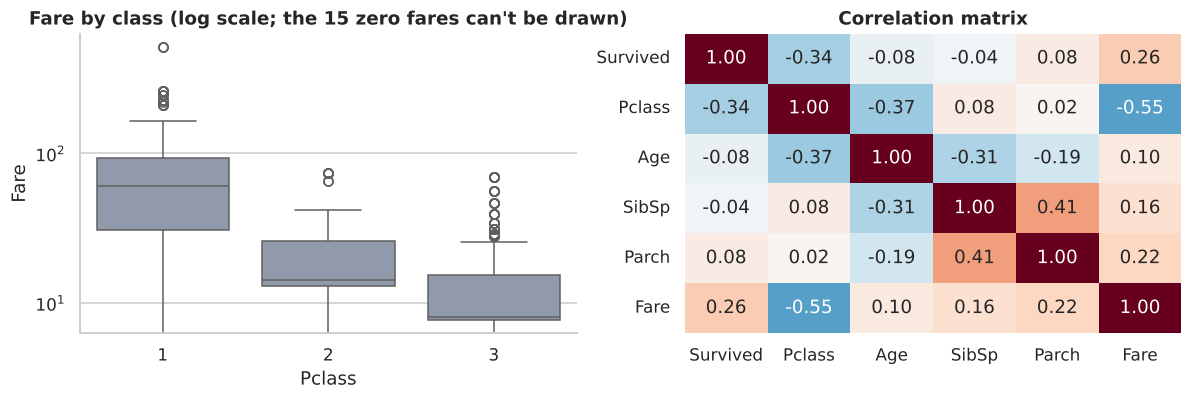

Correlation of Fare with Survived, within each class:
Pclass
1    0.19
2    0.10
3    0.00


In [9]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
sns.boxplot(data=df, x="Pclass", y="Fare", color=PAL["grey"], ax=ax[0]); ax[0].set_yscale("log"); ax[0].set_title("Fare by class (log scale; the 15 zero fares can't be drawn)")
num = df[["Survived", "Pclass", "Age", "SibSp", "Parch", "Fare"]].corr()
sns.heatmap(num, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1, cbar=False, ax=ax[1])
ax[1].set_title("Correlation matrix")
plt.tight_layout(); plt.show()
print("Correlation of Fare with Survived, within each class:")
print(df.groupby("Pclass").apply(lambda g: g.Fare.corr(g.Survived), include_groups=False).round(2).to_string())

Fare correlates with survival at 0.26 overall, but **the within-class correlations are 0.19 (first), 0.10 (second) and 0.00 (third)**. Money mattered mostly because it bought a class of ticket. Inside third class, paying more bought nothing. Fare and Pclass are also strongly (negatively) correlated at -0.55, so they carry overlapping information; keep this in mind before putting both into a model.

## 3. Outliers and extreme values

In [10]:
q1, q3 = df.Fare.quantile([.25, .75]); upper = q3 + 1.5 * (q3 - q1)
print(f"Fare IQR rule: upper fence = {upper:.1f}  ->  {int((df.Fare > upper).sum())} passengers flagged ({(df.Fare > upper).mean():.0%})")
print("Within-class fences:")
for c in [1, 2, 3]:
    s = df[df.Pclass == c].Fare; a, b = s.quantile([.25, .75]); f = b + 1.5 * (b - a)
    print(f"  class {c}: fence {f:5.1f}  flagged {int((s > f).sum())}")
df.nlargest(8, "Fare")[["Name", "Pclass", "Fare", "Ticket", "Survived"]]

Fare IQR rule: upper fence = 65.6  ->  116 passengers flagged (13%)
Within-class fences:
  class 1: fence 187.4  flagged 20
  class 2: fence  45.5  flagged 7
  class 3: fence  27.1  flagged 52


,Name,Pclass,Fare,Ticket,Survived
258,"Ward, Miss. Anna",1,512.3292,PC 17755,1
679,"Cardeza, Mr. Thomas Drake Martinez",1,512.3292,PC 17755,1
737,"Lesurer, Mr. Gustave J",1,512.3292,PC 17755,1
27,"Fortune, Mr. Charles Alexander",1,263.0000,19950,0
88,"Fortune, Miss. Mabel Helen",1,263.0000,19950,1
341,"Fortune, Miss. Alice Elizabeth",1,263.0000,19950,1
438,"Fortune, Mr. Mark",1,263.0000,19950,0
311,"Ryerson, Miss. Emily Borie",1,262.3750,PC 17608,1


Using one IQR rule across everyone flags 116 passengers (13%), which is too many to call "outliers". They are mostly just first class, where a high fare is normal; the class-specific fences flag far fewer (20 / 7 / 52). The genuine extremes are the three passengers on ticket PC 17755 at £512.33.

Does that look like a data-entry error? Probably not. A fare that high on a first-class suite ticket is consistent with the class pattern. I would **keep** these values and use log(fare) rather than deleting rows.

In [11]:
print("Fare == 0:", int((df.Fare == 0).sum()), "passengers")
df[df.Fare == 0][["Name", "Pclass", "Embarked", "Survived"]]

Fare == 0: 15 passengers


,Name,Pclass,Embarked,Survived
179,"Leonard, Mr. Lionel",3,S,0
263,"Harrison, Mr. William",1,S,0
271,"Tornquist, Mr. William Henry",3,S,1
277,"Parkes, Mr. Francis ""Frank""",2,S,0
302,"Johnson, Mr. William Cahoone Jr",3,S,0
413,"Cunningham, Mr. Alfred Fleming",2,S,0
466,"Campbell, Mr. William",2,S,0
481,"Frost, Mr. Anthony Wood ""Archie""",2,S,0
597,"Johnson, Mr. Alfred",3,S,0
633,"Parr, Mr. William Henry Marsh",1,S,0


15 passengers have a fare of exactly 0, all men, all boarded at Southampton, and only 1 of 15 survived. Free tickets are unusual for a paying passenger, so these are either missing values coded as zero or special cases, plausibly staff or guests travelling free (Thomas Andrews, the ship's designer, is on the list). We cannot tell which from the file alone. Treating them as missing and imputing is the safer default for a model; for EDA I would flag them with a binary feature rather than silently overwrite.

In [12]:
print("Extreme family sizes (SibSp >= 5):")
df[df.SibSp >= 5][["Name", "SibSp", "Parch", "Pclass", "Survived"]].sort_values("Name")

Extreme family sizes (SibSp >= 5):


,Name,SibSp,Parch,Pclass,Survived
480,"Goodwin, Master. Harold Victor",5,2,3,0
386,"Goodwin, Master. Sidney Leonard",5,2,3,0
59,"Goodwin, Master. William Frederick",5,2,3,0
71,"Goodwin, Miss. Lillian Amy",5,2,3,0
683,"Goodwin, Mr. Charles Edward",5,2,3,0
159,"Sage, Master. Thomas Henry",8,2,3,0
180,"Sage, Miss. Constance Gladys",8,2,3,0
863,"Sage, Miss. Dorothy Edith ""Dolly""",8,2,3,0
792,"Sage, Miss. Stella Anna",8,2,3,0
846,"Sage, Mr. Douglas Bullen",8,2,3,0


`SibSp` of 5 or 8 looks like an outlier but is real: it is two families (Goodwin, Sage), all third class, and **all 12 died**. These are valid data points and they matter, since they are a large part of why big families look doomed in Step 5.

## 4. Missing values

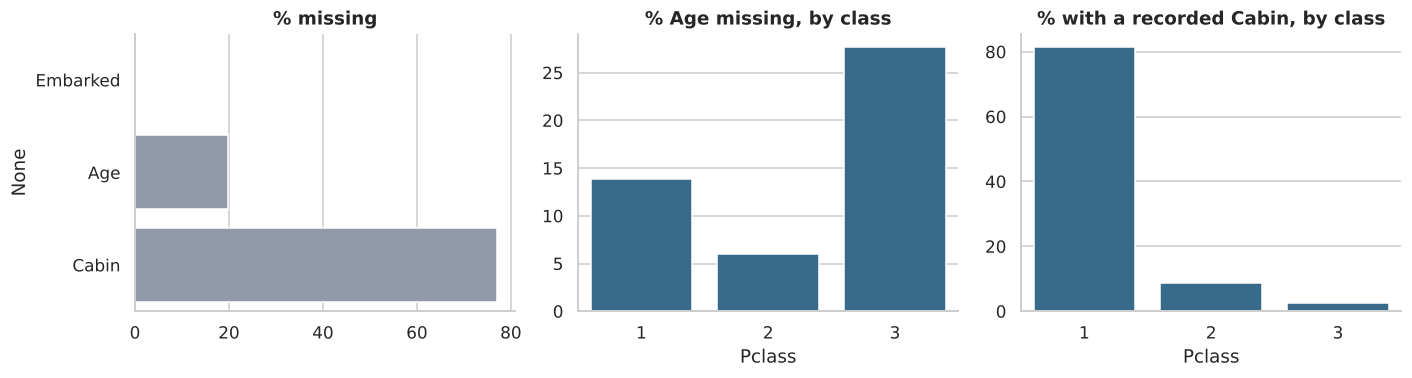

Survival rate when Age is missing vs known:
Age
Age known      0.406
Age missing    0.294


In [13]:
fig, ax = plt.subplots(1, 3, figsize=(13, 3.6))
m = (df.isna().mean() * 100); m = m[m > 0].sort_values()
sns.barplot(x=m.values, y=m.index, color=PAL["grey"], ax=ax[0]); ax[0].set_title("% missing"); ax[0].set_xlabel("")
a = df.assign(AgeMissing=df.Age.isna()).groupby("Pclass").AgeMissing.mean() * 100
sns.barplot(x=a.index, y=a.values, color=PAL["lived"], ax=ax[1]); ax[1].set_title("% Age missing, by class"); ax[1].set_xlabel("Pclass")
c = df.assign(HasCabin=df.Cabin.notna()).groupby("Pclass").HasCabin.mean() * 100
sns.barplot(x=c.index, y=c.values, color=PAL["lived"], ax=ax[2]); ax[2].set_title("% with a recorded Cabin, by class"); ax[2].set_xlabel("Pclass")
plt.tight_layout(); plt.show()
print("Survival rate when Age is missing vs known:")
print(df.groupby(df.Age.isna()).Survived.mean().round(3).rename({False: "Age known", True: "Age missing"}).to_string())

The missingness is **not random**:
- **Age**: 28% of third class is missing vs 14% of first and 6% of second. Passengers with no age had a 29% survival rate against 41% for those with one. Dropping those rows would bias the sample.
- **Cabin**: 81% of first class has a cabin number against 2-9% of the others, so "has a cabin" is largely a proxy for class. That also means it should not be treated as an independent predictor.
- **Embarked**: only 2 rows, so almost anything works.

**Cabin**: too sparse to fill. We will extract the deck letter and add a `HasCabin` flag instead (Step 5).
**Age**: a global median would ignore that children and adults differ a lot. We fill by the median of the passenger's title (Mr / Mrs / Miss / Master / Rare) within their class, since `Master` is a title for boys and tells us a child, while `Mr` tells us an adult. We also keep an `AgeMissing` flag because the missingness itself carries signal.

In [14]:
# Title is needed for Age imputation; extract it from Name, e.g. "Braund, Mr. Owen Harris" -> "Mr"
df["Title"] = df.Name.str.extract(r",\s*([^\.]+)\.", expand=False).replace({"Mlle": "Miss", "Ms": "Miss", "Mme": "Mrs"})
df["Title"] = df.Title.where(df.Title.isin(["Mr", "Mrs", "Miss", "Master"]), "Rare")
print(df.Title.value_counts().to_string())
print()
print(df.groupby("Title").Age.median().round(1).to_string())

Title
Mr        517
Miss      185
Mrs       126
Master     40
Rare       23

Title
Master     3.5
Miss      21.0
Mr        30.0
Mrs       35.0
Rare      48.5


In [15]:
df["AgeMissing"] = df.Age.isna().astype(int)
df["AgeFilled"] = df.Age.fillna(df.groupby(["Title", "Pclass"]).Age.transform("median"))
print("Age still missing after fill:", df.AgeFilled.isna().sum())
print("Median before / after:", df.Age.median(), "/", df.AgeFilled.median())

Age still missing after fill: 0
Median before / after: 28.0 / 26.0


Every gap is filled, and the overall median barely moves (28 to 26), because most missing ages are third-class adults. A quick sanity check is that the filled values should not change the shape of the distribution much; the histogram below compares them.

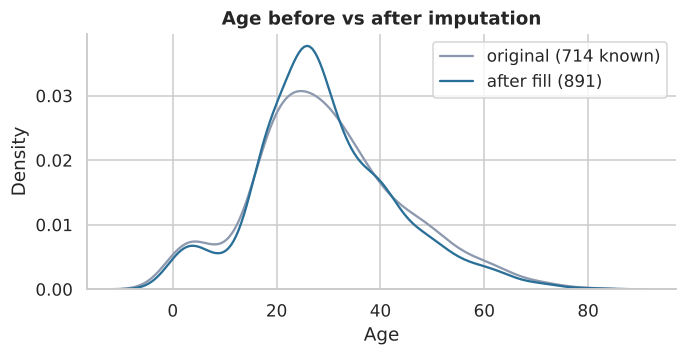

In [16]:
fig, ax = plt.subplots(figsize=(6.5, 3.4))
sns.kdeplot(df.Age.dropna(), label="original (714 known)", color=PAL["grey"], ax=ax)
sns.kdeplot(df.AgeFilled, label="after fill (891)", color=PAL["lived"], ax=ax)
ax.legend(); ax.set_title("Age before vs after imputation"); plt.tight_layout(); plt.show()

The fill creates a visible spike around the group medians (a known side effect of median imputation), which shrinks the variance slightly. Fine for EDA; if we were building a model, we would consider a model-based fill and test sensitivity.

**Embarked, two missing rows.** Both are first-class women sharing ticket 113572, fare £80, cabin B28. A tempting data-driven guess is to match the fare to the port whose first-class median fare is closest.

In [17]:
print("Median first-class fare by port:")
print(df[df.Pclass == 1].groupby("Embarked").Fare.median().round(1).to_string())
print("\nMost common port overall:", df.Embarked.mode()[0])
df[df.Embarked.isna()][["Name", "Pclass", "Fare", "Ticket", "Cabin"]]

Median first-class fare by port:
Embarked
C    78.3
Q    90.0
S    52.0

Most common port overall: S


,Name,Pclass,Fare,Ticket,Cabin
61,"Icard, Miss. Amelie",1,80.0,113572,B28
829,"Stone, Mrs. George Nelson (Martha Evelyn)",1,80.0,113572,B28


The fare heuristic points to Cherbourg (£78 is closest to £80), while the mode says Southampton. The historical record settles it: Encyclopedia Titanica states that Amelie Icard "boarded the Titanic at Southampton as maid to Mrs George Nelson Stone", and she travelled on Mrs Stone's ticket ([Encyclopedia Titanica](https://encyclopedia-titanica.org/titanic-survivor/amelia-icard.html)). The simple mode fill is right and the clever fare-matching would have been wrong. For two rows it hardly matters statistically, but it is a good warning against over-engineering an imputation.

In [18]:
df["Embarked"] = df.Embarked.fillna("S")
print("Missing after cleaning ->", df[["Age", "AgeFilled", "Embarked"]].isna().sum().to_dict())

Missing after cleaning -> {'Age': 177, 'AgeFilled': 0, 'Embarked': 0}


## 5. Feature engineering
New columns built from what we already have: `Title` (done above), family size, a lone-traveller flag, deck, cabin flag, ticket-group size, fare per person, an age band and a zero-fare flag.

In [19]:
df["FamilySize"] = df.SibSp + df.Parch + 1
df["IsAlone"] = (df.FamilySize == 1).astype(int)
df["HasCabin"] = df.Cabin.notna().astype(int)
df["Deck"] = df.Cabin.str[0].fillna("Unknown")
df["TicketGroup"] = df.groupby("Ticket").Ticket.transform("count")
df["FarePerPerson"] = df.Fare / df.TicketGroup
df["ZeroFare"] = (df.Fare == 0).astype(int)
df["AgeBand"] = pd.cut(df.AgeFilled, [0, 12, 18, 35, 60, 100], labels=["0-12", "13-18", "19-35", "36-60", "60+"])
print("Tickets whose rows disagree on Fare:", int((df.groupby("Ticket").Fare.nunique() > 1).sum()), "of", df.Ticket.nunique())
print("\nMedian fare by class, as recorded vs divided by ticket-group size:")
print(df.groupby("Pclass")[["Fare", "FarePerPerson"]].median().round(2).to_string())
df[["Name", "Title", "FamilySize", "IsAlone", "Deck", "TicketGroup", "Fare", "FarePerPerson"]].head(6)

Tickets whose rows disagree on Fare: 1 of 681

Median fare by class, as recorded vs divided by ticket-group size:
         Fare  FarePerPerson
Pclass                      
1       60.29          35.25
2       14.25          13.00
3        8.05           7.85


,Name,Title,FamilySize,IsAlone,Deck,TicketGroup,Fare,FarePerPerson
0,"Braund, Mr. Owen Harris",Mr,2,0,Unknown,1,7.2500,7.2500
1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",Mrs,2,0,C,1,71.2833,71.2833
2,"Heikkinen, Miss. Laina",Miss,1,1,Unknown,1,7.9250,7.9250
3,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",Mrs,2,0,C,2,53.1000,26.5500
4,"Allen, Mr. William Henry",Mr,1,1,Unknown,1,8.0500,8.0500
5,"Moran, Mr. James",Mr,1,1,Unknown,1,8.4583,8.4583


A data-quality finding: 344 passengers share a ticket with someone else, and in 680 of 681 tickets everyone on the ticket has the same `Fare`. So it is **not obvious whether `Fare` is the price per person or the total for the ticket**. `FarePerPerson` is a sensitivity feature. Dividing by group size moves the first-class median from about £60 to £35, while second and third class barely change (£14 to £13 and £8 to £8), because they mostly travel on single tickets. That is what we would expect if shared-ticket fares were group totals, but it is only suggestive. We cannot prove it from this file, so treat `Fare` with care.

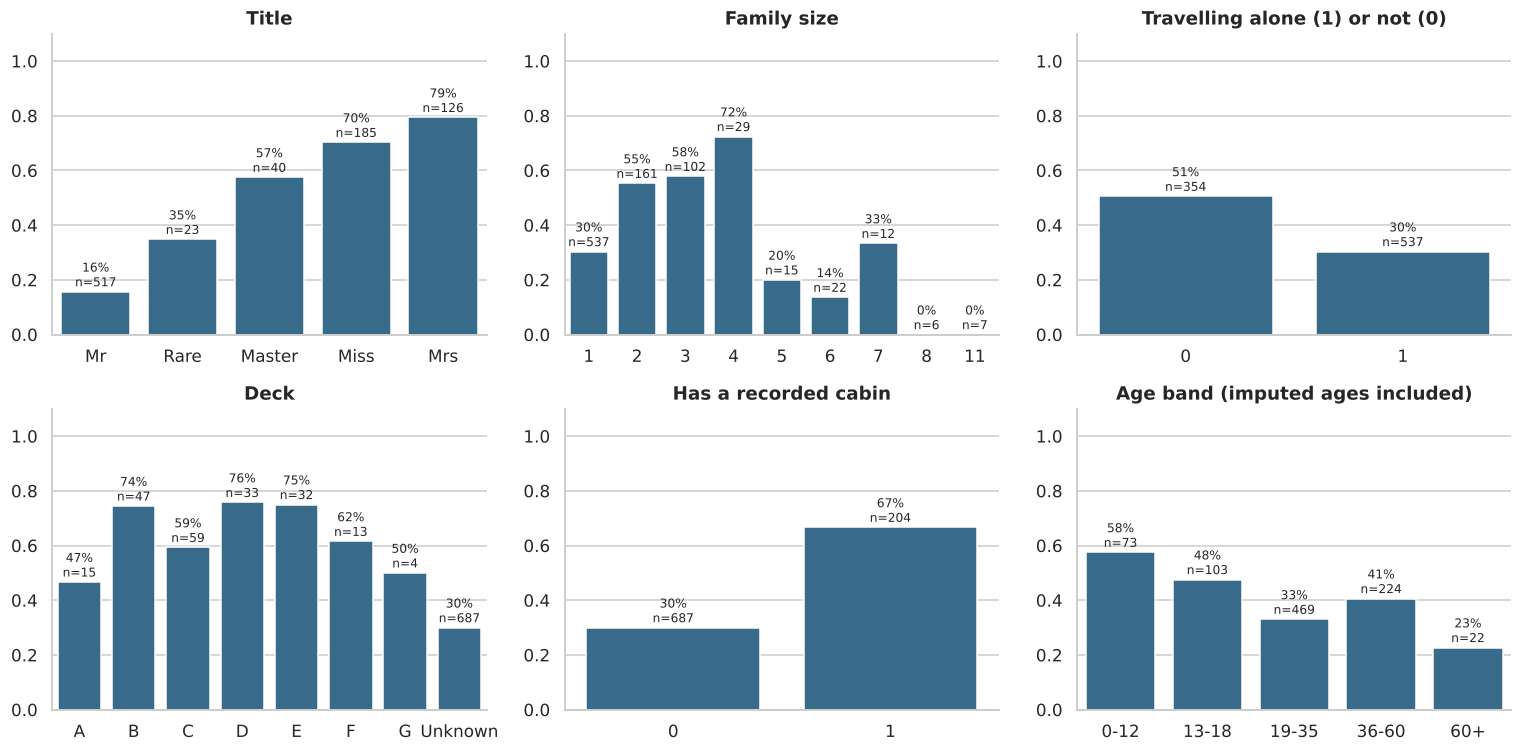

In [20]:
def rate_plot(ax, col, title, order=None):
    r = df.groupby(col, observed=True).Survived.agg(["mean", "count"])
    if order: r = r.loc[order]
    sns.barplot(x=r.index.astype(str), y=r["mean"], color=PAL["lived"], ax=ax)
    for i, (m_, n_) in enumerate(zip(r["mean"], r["count"])):
        ax.text(i, m_ + .02, f"{m_:.0%}\nn={n_}", ha="center", fontsize=8)
    ax.set_title(title); ax.set_xlabel(""); ax.set_ylim(0, 1.1); ax.set_ylabel("")

fig, ax = plt.subplots(2, 3, figsize=(14, 7))
rate_plot(ax[0, 0], "Title", "Title", ["Mr", "Rare", "Master", "Miss", "Mrs"])
rate_plot(ax[0, 1], "FamilySize", "Family size")
rate_plot(ax[0, 2], "IsAlone", "Travelling alone (1) or not (0)")
rate_plot(ax[1, 0], "Deck", "Deck", ["A", "B", "C", "D", "E", "F", "G", "Unknown"])
rate_plot(ax[1, 1], "HasCabin", "Has a recorded cabin")
rate_plot(ax[1, 2], "AgeBand", "Age band (imputed ages included)")
plt.tight_layout(); plt.show()

What the engineered features show:
- **Title** is the strongest single feature: Mr 16%, Master 57%, Miss 70%, Mrs 79%. It bundles sex, age and marital status in a single column.
- **Family size is non-monotonic**: solo travellers 30%, small families of 2-4 around 55-72%, then families of 5 and above do badly (14-33% for sizes 5 to 7, and none of the 13 passengers in families of 8 or 11 survived). A linear model would miss this, so it needs bucketing.
- **Deck / HasCabin**: passengers with a cabin survived at 67% vs 30% without. Treat this with care, since it is mostly class again (previous section), and decks cluster on the first-class end of the ship.
- **Rare titles are a mixed bag** (35%, n=23): clergy, military men and nobility, which is too few and too varied to say much.

In [21]:
print("Is 'travelling alone' a real effect, or sex in disguise?  Survival rate by sex and IsAlone:")
print(df.pivot_table(index="Sex", columns="IsAlone", values="Survived", aggfunc=["mean", "count"]).round(2).to_string())
print("\nFamily size inside third class only (is the big-family penalty just class?):")
print(df[df.Pclass == 3].groupby("FamilySize").Survived.agg(["mean", "count"]).round(2).T.to_string())

Is 'travelling alone' a real effect, or sex in disguise?  Survival rate by sex and IsAlone:
         mean       count     
IsAlone     0     1     0    1
Sex                           
female   0.71  0.79   188  126
male     0.27  0.16   166  411

Family size inside third class only (is the big-family penalty just class?):
FamilySize      1      2      3     4     5     6      7    8    11
mean          0.21   0.35   0.43  0.67   0.0   0.0   0.33  0.0  0.0
count       324.00  57.00  47.00  9.00  12.0  17.0  12.00  6.0  7.0


Two checks on the feature stories:
- **"Alone" is mostly a sex effect.** Lone men survive at 16% vs 27% for men with family. For women the direction flips (79% alone vs 71% with family). Raw "IsAlone" averages over two groups heading in different directions, so on its own it is a weak, misleading feature.
- **The big-family penalty survives within third class** (four of the five sizes from 5 up sit at 0%; size 7 is at 33%), so it is not only a class artefact, though the small cells (6 to 17 passengers each) mean it should be read as indicative.

## Summary of findings

| # | Finding | Evidence | Confidence |
|---|---|---|---|
| 1 | Sex is the dominant predictor | 74% of women vs 19% of men survived | High |
| 2 | Class matters, and interacts with sex | Women: 97% / 92% / 50% by class; men: 37% / 16% / 14% | High |
| 3 | Children were prioritised, but only boys show it | Boys 0-12 survive at ~57%; males 13+ at 9-19% | Medium (small cells) |
| 4 | Port of embarkation is mostly class in disguise | Cherbourg 51% first class; Queenstown 94% third | High |
| 5 | Fare effect is a class effect | Fare vs survival: 0.26 overall, 0.19 / 0.10 / 0.00 within class | High |
| 6 | Missing ages are not random | 28% of 3rd class missing vs 6% of 2nd; 29% vs 41% survival | High |
| 7 | Family size is non-linear | 1: 30%, 4: 72%, 5+: 0-33% | Medium |
| 8 | `Fare` may be a ticket total, not per person | 344 passengers share tickets with identical fares | Medium (cannot confirm from file) |

**Data issues to carry forward:** Cabin and Age gaps (handled with a deck/flag and a title-by-class fill), 15 zero fares, a right-skewed Fare (use log), and a sample that is not the whole ship.

**What I would not claim:** that any of these is causal. This is observational data, and sex, class, age and family are tangled together. A model would be the next step, but EDA alone cannot separate them.